<a href="https://colab.research.google.com/github/anytaaly/Driving-Behavior-Evaluation/blob/main/Driving_Behavior_SVM_vs_Neural_Network.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Streaming Driving Behavior Evaluation: SVM vs. Neural Network
project is part of Final project for University of Pennsylvania


Compare an RBF support vector machine with a PyTorch neural network on smartphone motion sensors. Replay held-out readings through a bounded buffer, predict behavior, and update metrics after delayed labels arrive.

**Research question:** Which model best balances macro-F1, aggressive-driving recall, and per-window processing latency?

**Hypothesi
s:** Window statistics carry more behavioral signal than a class-frequency baseline; neither SVM nor neural network is assumed to win.

This is an offline-trained classifier with simulated streaming inference, not online learning or a vehicle-control system. Labels describe broad driving styles, not specific braking/turning events or crash risk. Developed with AI assistance; review and extend before presenting as your completed research.

## Run in Google Colab
1.
2. Use a **CPU runtime**; no paid API or GPU is needed.
3. Choose **Runtime → Run all**. Data downloads automatically from Kaggle. If Kaggle blocks the download, upload its two CSVs into `data/driving/` and rerun.
4. Review the results, failure cases and limitations. The last cell creates a downloadable results ZIP. Save your executed notebook before pushing it to GitHub.

## System design
Raw readings → continuity checks → non-overlapping trailing windows → shared feature extraction → training-only standardization → SVM / neural network → prediction log → delayed-label evaluator.

**Important experimental limit:** There are no driver or trip identifiers. We preserve the publisher's train/test files and create validation tails within training recording segments. Those inferred segments are not verified trips. We cannot claim driver-independent generalization.

**Validation status:** All ten analysis code cells executed successfully in order in an isolated local Python process. The dependency-installation cell was skipped because packages were preinstalled. Outputs are included; hosted Google Colab execution has not been verified. Streaming feature vectors and predictions matched the offline pipeline exactly.

In [1]:
%pip -q install 'numpy>=1.26,<3' 'pandas>=2.2,<3' 'scikit-learn>=1.5,<1.8' 'matplotlib>=3.8,<4' 'torch>=2.2,<3' joblib

In [2]:
import copy, hashlib, io, json, random, time, urllib.request, zipfile, platform
from pathlib import Path
from collections import deque
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, ConfusionMatrixDisplay, recall_score)
import joblib
SEED=42
random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
torch.set_num_threads(2)
torch.use_deterministic_algorithms(True)
SENSORS=['AccX','AccY','AccZ','GyroX','GyroY','GyroZ']
WINDOW=10              # approximately five seconds at the stated 2 Hz sampling rate
STRIDE=WINDOW           # no overlapping raw observations across windows
MAX_GAP_SECONDS=2       # operational continuity policy, not a trip identifier
EPOCHS=150;PATIENCE=20
OUT=Path('driving_results');OUT.mkdir(exist_ok=True)
print('Python',platform.python_version(),'PyTorch',torch.__version__,'device: CPU')

Python 3.13.18 PyTorch 2.11.0+cpu device: CPU


## 1. Download and audit the source
[Kaggle Driving Behavior](https://www.kaggle.com/datasets/outofskills/driving-behavior), credited to Paul-Stefan Popescu and Ion Cojocaru. The data card lists accelerometer and gyroscope recordings, three behavior labels, and a 2 Hz nominal sampling rate, under CC BY 4.0. Consult the source for units and collection details before physical interpretation.

Timestamps have integer-second resolution, so repeated timestamps are expected;

 Preserve source row order. We check sensor values, missing fields, duplicate sensor+timestamp records, and overlap between publisher files. Sensor magnitudes are descriptive signals, not calibrated physical risk scores.

train_motion_data.csv rows: 3644 duplicate sensor/timestamp rows: 0


,rows,labels,start,end
segment,,,,
0,1200,NORMAL,3581629,3582276
1,1113,AGGRESSIVE,3582366,3582966
2,536,SLOW,3583044,3583333
3,795,SLOW,3583363,3583791


test_motion_data.csv rows: 3084 duplicate sensor/timestamp rows: 0


,rows,labels,start,end
segment,,,,
0,814,AGGRESSIVE,818922,819361
1,997,NORMAL,819440,819978
2,1273,SLOW,820022,820709


Class,AGGRESSIVE,NORMAL,SLOW
split,,,
publisher_test,814,997,1273
publisher_train,1113,1200,1331


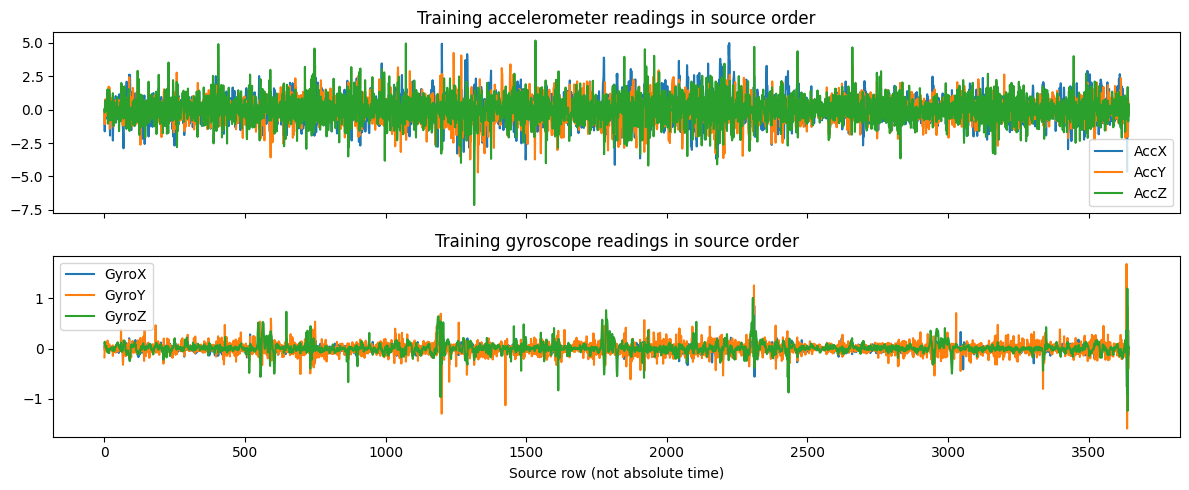

In [3]:
root=Path('data/driving');root.mkdir(parents=True,exist_ok=True)
expected=['train_motion_data.csv','test_motion_data.csv']
if not all((root/name).exists() for name in expected):
    url='https://www.kaggle.com/api/v1/datasets/download/outofskills/driving-behavior'
    try:
        with urllib.request.urlopen(url,timeout=90) as r: payload=r.read()
        with zipfile.ZipFile(io.BytesIO(payload)) as z:
            for name in expected:
                matching=[v for v in z.namelist() if Path(v).name==name]
                if len(matching)!=1:raise ValueError('Unexpected dataset archive schema')
                (root/name).write_bytes(z.read(matching[0]))
    except Exception as exc:
        raise RuntimeError('Download failed. Manually download the Kaggle ZIP and put its two CSVs in data/driving/. No synthetic fallback is used.') from exc
frames={};manifest=[]
for name in expected:
    path=root/name;df=pd.read_csv(path)
    assert set(SENSORS+['Timestamp','Class'])<=set(df.columns)
    df['Class']=df.Class.astype(str).str.strip().str.upper()
    assert set(df.Class)=={'SLOW','NORMAL','AGGRESSIVE'}
    assert np.isfinite(df[SENSORS+['Timestamp']].to_numpy(dtype=float)).all()
    df['source_row']=np.arange(len(df))
    delta=df.Timestamp.diff()
    df['segment']=(delta.lt(0)|delta.gt(MAX_GAP_SECONDS)).cumsum()
    print(name,'rows:',len(df),'duplicate sensor/timestamp rows:',df.duplicated(SENSORS+['Timestamp']).sum())
    display(df.groupby('segment').agg(rows=('Class','size'),labels=('Class',lambda s:','.join(s.unique())),start=('Timestamp','min'),end=('Timestamp','max')))
    frames[name]=df
    manifest.append({'filename':name,'rows':len(df),'sha256':hashlib.sha256(path.read_bytes()).hexdigest()})
train_raw=frames[expected[0]];test_raw=frames[expected[1]]
train_keys=set(pd.util.hash_pandas_object(train_raw[SENSORS+['Timestamp']],index=False))
test_keys=set(pd.util.hash_pandas_object(test_raw[SENSORS+['Timestamp']],index=False))
assert not train_keys & test_keys,'Exact overlapping sensor/timestamp rows require investigation.'
(OUT/'data_manifest.json').write_text(json.dumps(manifest,indent=2))
combined=pd.concat([train_raw.assign(split='publisher_train'),test_raw.assign(split='publisher_test')],ignore_index=True)
display(pd.crosstab(combined.split,combined.Class))
fig,axes=plt.subplots(2,1,figsize=(12,5),sharex=True)
train_raw[SENSORS[:3]].plot(ax=axes[0],title='Training accelerometer readings in source order')
train_raw[SENSORS[3:]].plot(ax=axes[1],title='Training gyroscope readings in source order')
axes[1].set_xlabel('Source row (not absolute time)');plt.tight_layout();plt.show()

## 2. Split before extracting windows
A global chronological split would place entire classes in different partitions because the source recordings are arranged in behavior blocks. Instead, reserve the last 25% of **each timestamp-contiguous training segment** for validation, with a ten-reading purge gap. The independent publisher test file remains untouched for selection.

This is within-recording validation and may still be optimistic. Use new drivers, phones and trips for a stronger follow-up study. Segment boundaries use timestamps only, never labels. We do not feed timestamp, segment ID, row index or class into the model.

For each ten-reading window, calculate mean, standard deviation, minimum, maximum and RMS for each axis, plus acceleration/rotation magnitude statistics and mean absolute first differences. Both models receive exactly the same features. The supervised target is the **last reading's label**; mixed-label windows are retained and marked for error analysis.

In [4]:
def feature_vector(values):
    a=np.asarray(values,dtype=np.float64)
    assert a.shape==(WINDOW,len(SENSORS)) and np.isfinite(a).all()
    parts=[a.mean(0),a.std(0),a.min(0),a.max(0),np.sqrt((a*a).mean(0)),np.abs(np.diff(a,axis=0)).mean(0)]
    for group in [a[:,:3],a[:,3:]]:
        mag=np.linalg.norm(group,axis=1)
        parts.append(np.array([mag.mean(),mag.std(),mag.max()]))
    return np.concatenate(parts).astype(np.float32)
FEATURE_NAMES=[f'{stat}_{axis}' for stat in ['mean','std','min','max','rms','mean_abs_delta'] for axis in SENSORS]+[f'{sensor}_magnitude_{stat}' for sensor in ['acc','gyro'] for stat in ['mean','std','max']]
assert len(FEATURE_NAMES)==42

def make_windows(frame):
    features=[];meta=[]
    for segment,g in frame.groupby('segment',sort=False):
        for start in range(0,len(g)-WINDOW+1,STRIDE):
            w=g.iloc[start:start+WINDOW]
            features.append(feature_vector(w[SENSORS].to_numpy()))
            meta.append({'segment':int(segment),'start_row':int(w.source_row.iloc[0]),'end_row':int(w.source_row.iloc[-1]),
              'timestamp':float(w.Timestamp.iloc[-1]),'label':w.Class.iloc[-1],
              'mixed_labels':w.Class.nunique()>1,'window_elapsed_seconds':float(w.Timestamp.iloc[-1]-w.Timestamp.iloc[0])})
    return np.stack(features),pd.DataFrame(meta)
train_parts=[];val_parts=[]
for _,g in train_raw.groupby('segment',sort=False):
    cut=int(.75*len(g))
    assert cut>WINDOW and len(g)-cut-WINDOW>=WINDOW
    train_parts.append(g.iloc[:cut]);val_parts.append(g.iloc[cut+WINDOW:])
train_part=pd.concat(train_parts);val_part=pd.concat(val_parts)
assert not set(train_part.source_row)&set(val_part.source_row)
Xtr,mtr=make_windows(train_part);Xva,mva=make_windows(val_part);Xte,mte=make_windows(test_raw)
encoder=LabelEncoder().fit(mtr.label);classes=encoder.classes_;K=len(classes)
ytr=encoder.transform(mtr.label);yva=encoder.transform(mva.label);yte=encoder.transform(mte.label)
for split,y in [('train',ytr),('validation',yva),('test',yte)]:
    assert len(np.unique(y))==K
    print(split,len(y),dict(zip(classes,np.bincount(y,minlength=K))))
scaler=StandardScaler().fit(Xtr)
Ztr=scaler.transform(Xtr).astype(np.float32);Zva=scaler.transform(Xva).astype(np.float32);Zte=scaler.transform(Xte).astype(np.float32)
assert np.allclose(scaler.mean_,Xtr.mean(axis=0),rtol=1e-5,atol=1e-6)
print('Feature count:',Xtr.shape[1],'mixed-label test windows:',int(mte.mixed_labels.sum()))
display(mte.head())

train 272 {'AGGRESSIVE': np.int64(83), 'NORMAL': np.int64(90), 'SLOW': np.int64(99)}
validation 85 {'AGGRESSIVE': np.int64(26), 'NORMAL': np.int64(29), 'SLOW': np.int64(30)}
test 307 {'AGGRESSIVE': np.int64(81), 'NORMAL': np.int64(99), 'SLOW': np.int64(127)}
Feature count: 42 mixed-label test windows: 0


,segment,start_row,end_row,timestamp,label,mixed_labels,window_elapsed_seconds
0,0,0,9,818927.0,AGGRESSIVE,False,5.0
1,0,10,19,818932.0,AGGRESSIVE,False,5.0
2,0,20,29,818938.0,AGGRESSIVE,False,5.0
3,0,30,39,818943.0,AGGRESSIVE,False,5.0
4,0,40,49,818949.0,AGGRESSIVE,False,5.0


## 3. Baseline and SVM selection
Macro-F1 gives equal importance to each class. I selected the SVM configuration using validation macro-F1 only. RBF SVM training does not produce neural-network epochs or a directly comparable cross-entropy curve; report its validation grid and classification errors instead.

,configuration,validation_macro_f1,train_error,validation_error,fit_seconds
4,"C=1, gamma=0.01",0.474615,0.349265,0.505882,0.011582
7,"C=10, gamma=0.01",0.468661,0.172794,0.529412,0.007887
5,"C=1, gamma=0.1",0.465746,0.055147,0.505882,0.013066
3,"C=1, gamma=scale",0.449620,0.253676,0.529412,0.012019
6,"C=10, gamma=scale",0.443999,0.062500,0.552941,0.014186
8,"C=10, gamma=0.1",0.401652,0.000000,0.564706,0.008505
1,"C=0.1, gamma=0.01",0.386876,0.518382,0.517647,0.012572
0,"C=0.1, gamma=scale",0.363822,0.522059,0.541176,0.013666
2,"C=0.1, gamma=0.1",0.257672,0.408088,0.635294,0.012541


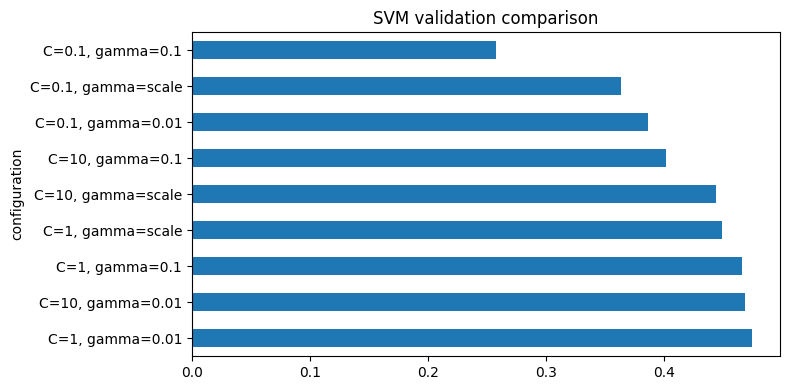

In [6]:
baseline=DummyClassifier(strategy='most_frequent').fit(Ztr,ytr)
svm_rows=[];svms={}
for C in [.1,1,10]:
    for gamma in ['scale',.01,.1]:
        model=SVC(C=C,gamma=gamma,kernel='rbf',class_weight='balanced')
        start=time.perf_counter();model.fit(Ztr,ytr);seconds=time.perf_counter()-start
        pred=model.predict(Zva);key=f'C={C}, gamma={gamma}'
        svms[key]=model
        svm_rows.append({'configuration':key,'validation_macro_f1':f1_score(yva,pred,average='macro'),
          'train_error':1-accuracy_score(ytr,model.predict(Ztr)),'validation_error':1-accuracy_score(yva,pred),'fit_seconds':seconds})
svm_selection=pd.DataFrame(svm_rows).sort_values('validation_macro_f1',ascending=False,kind='stable')
best_svm_key=svm_selection.iloc[0].configuration;svm=svms[best_svm_key]
display(svm_selection)
svm_selection.plot.barh(x='configuration',y='validation_macro_f1',legend=False,figsize=(8,4),title='SVM validation comparison');plt.tight_layout();plt.show()
svm_selection.to_csv(OUT/'svm_selection.csv',index=False)

## 4. Train a PyTorch neural network
Architecture: **42 inputs → 64 ReLU → dropout → 32 ReLU → 3 logits**. Cross-entropy uses training class weights; Adam updates parameters with backpropagation. Retain the checkpoint with lowest validation loss and stop after 20 epochs without improvement. The test set never determines the epoch.

Both train and validation losses below are measured in evaluation mode after each epoch, with the same class-weighted loss. Classification error is the fraction of incorrect predictions. Dropout is disabled during evaluation.

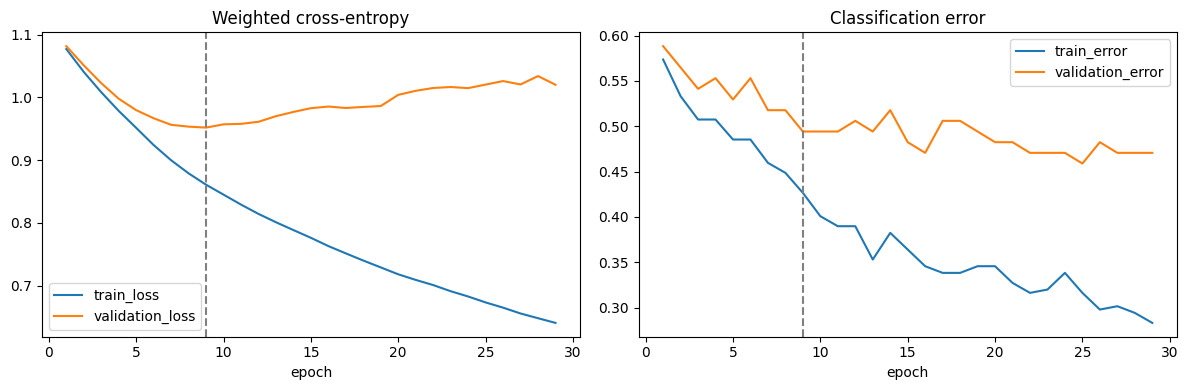

Selected epoch: 9 training seconds: 0.799


In [7]:
def make_network():
    return nn.Sequential(nn.Linear(len(FEATURE_NAMES),64),nn.ReLU(),nn.Dropout(.2),
                         nn.Linear(64,32),nn.ReLU(),nn.Linear(32,K))
net=make_network()
counts=np.bincount(ytr,minlength=K)
weights=torch.tensor(len(ytr)/(K*counts),dtype=torch.float32)
criterion=nn.CrossEntropyLoss(weight=weights)
optimizer=torch.optim.Adam(net.parameters(),lr=.001,weight_decay=.001)
tx=torch.from_numpy(Ztr);ty=torch.tensor(ytr,dtype=torch.long)
vx=torch.from_numpy(Zva);vy=torch.tensor(yva,dtype=torch.long)
loader=DataLoader(TensorDataset(tx,ty),batch_size=32,shuffle=True,generator=torch.Generator().manual_seed(SEED))
history=[];best_loss=float('inf');best_state=None;wait=0;started=time.perf_counter()
for epoch in range(1,EPOCHS+1):
    net.train()
    for bx,by in loader:
        optimizer.zero_grad();loss=criterion(net(bx),by);loss.backward();optimizer.step()
    net.eval()
    with torch.inference_mode():
        tl=net(tx);vl=net(vx)
        train_loss=criterion(tl,ty).item();val_loss=criterion(vl,vy).item()
        tp=tl.argmax(1).numpy();vp=vl.argmax(1).numpy()
    history.append({'epoch':epoch,'train_loss':train_loss,'validation_loss':val_loss,
      'train_error':1-accuracy_score(ytr,tp),'validation_error':1-accuracy_score(yva,vp),
      'validation_macro_f1':f1_score(yva,vp,average='macro')})
    if val_loss<best_loss-1e-5:
        best_loss=val_loss;best_state=copy.deepcopy(net.state_dict());best_epoch=epoch;wait=0
    else:wait+=1
    if wait>=PATIENCE:break
nn_fit_seconds=time.perf_counter()-started
net.load_state_dict(best_state);net.eval()
history=pd.DataFrame(history)
fig,ax=plt.subplots(1,2,figsize=(12,4))
history.plot(x='epoch',y=['train_loss','validation_loss'],ax=ax[0],title='Weighted cross-entropy')
history.plot(x='epoch',y=['train_error','validation_error'],ax=ax[1],title='Classification error')
for a in ax:a.axvline(best_epoch,color='gray',ls='--',label='selected epoch')
plt.tight_layout();plt.show()
print('Selected epoch:',best_epoch,'training seconds:',round(nn_fit_seconds,3))
history.to_csv(OUT/'neural_network_history.csv',index=False)
def predict_nn(z):
    with torch.inference_mode():return net(torch.as_tensor(z,dtype=torch.float32)).argmax(1).numpy()

## 5. Final held-out comparison and error analysis
Compare both models once on the publisher's test file. Include the majority-class baseline. Examine per-class recall, particularly AGGRESSIVE, rather than accuracy alone. These estimates describe this small dataset, not unseen-driver safety performance.

Baseline
              precision    recall  f1-score   support

  AGGRESSIVE       0.00      0.00      0.00        81
      NORMAL       0.00      0.00      0.00        99
        SLOW       0.41      1.00      0.59       127

    accuracy                           0.41       307
   macro avg       0.14      0.33      0.20       307
weighted avg       0.17      0.41      0.24       307

SVM
              precision    recall  f1-score   support

  AGGRESSIVE       0.49      0.73      0.59        81
      NORMAL       0.28      0.15      0.20        99
        SLOW       0.56      0.59      0.57       127

    accuracy                           0.49       307
   macro avg       0.44      0.49      0.45       307
weighted avg       0.45      0.49      0.46       307

Neural network
              precision    recall  f1-score   support

  AGGRESSIVE       0.50      0.74      0.59        81
      NORMAL       0.28      0.13      0.18        99
        SLOW       0.57      0.62      0.59    

,model,accuracy,balanced_accuracy,macro_f1,aggressive_recall
0,Baseline,0.413681,0.333333,0.195084,0.000000
1,SVM,0.485342,0.490154,0.453049,0.728395
2,Neural network,0.495114,0.498034,0.455376,0.740741


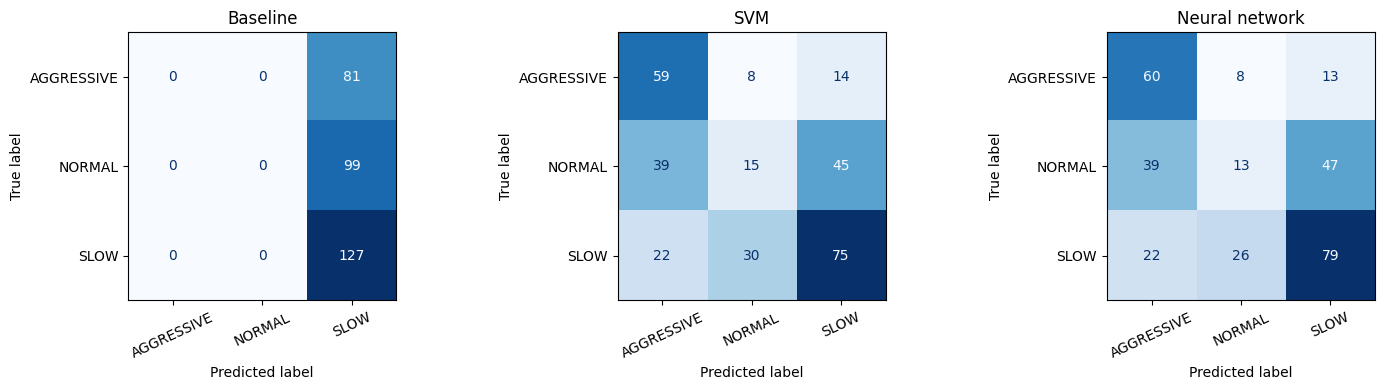

,segment,start_row,end_row,timestamp,label,mixed_labels,window_elapsed_seconds,Baseline,SVM,Neural network
2,0,20,29,818938.0,AGGRESSIVE,False,5.0,SLOW,SLOW,SLOW
3,0,30,39,818943.0,AGGRESSIVE,False,5.0,SLOW,SLOW,SLOW
4,0,40,49,818949.0,AGGRESSIVE,False,5.0,SLOW,SLOW,SLOW
5,0,50,59,818954.0,AGGRESSIVE,False,5.0,SLOW,SLOW,SLOW
7,0,70,79,818965.0,AGGRESSIVE,False,5.0,SLOW,SLOW,SLOW
12,0,120,129,818992.0,AGGRESSIVE,False,5.0,SLOW,NORMAL,NORMAL
34,0,340,349,819111.0,AGGRESSIVE,False,5.0,SLOW,SLOW,SLOW
38,0,380,389,819132.0,AGGRESSIVE,False,5.0,SLOW,NORMAL,SLOW
39,0,390,399,819138.0,AGGRESSIVE,False,5.0,SLOW,NORMAL,NORMAL
41,0,410,419,819148.0,AGGRESSIVE,False,5.0,SLOW,SLOW,AGGRESSIVE


In [8]:
predictors={'Baseline':baseline.predict,'SVM':svm.predict,'Neural network':predict_nn}
predictions={name:fn(Zte) for name,fn in predictors.items()}
rows=[]
for name,pred in predictions.items():
    rows.append({'model':name,'accuracy':accuracy_score(yte,pred),'balanced_accuracy':balanced_accuracy_score(yte,pred),
      'macro_f1':f1_score(yte,pred,average='macro'),'aggressive_recall':recall_score(yte,pred,labels=[int(encoder.transform(['AGGRESSIVE'])[0])],average='macro',zero_division=0)})
    print(name);print(classification_report(yte,pred,target_names=classes,zero_division=0))
metrics=pd.DataFrame(rows);display(metrics)
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,(name,pred) in zip(axes,predictions.items()):
    ConfusionMatrixDisplay.from_predictions(yte,pred,display_labels=classes,ax=ax,colorbar=False,cmap='Blues');ax.set_title(name);ax.tick_params(axis='x',rotation=25)
plt.tight_layout();plt.show()
errors=mte.copy()
for name,pred in predictions.items():errors[name]=encoder.inverse_transform(pred)
display(errors[(errors['SVM']!=errors.label)|(errors['Neural network']!=errors.label)].head(12))
metrics.to_csv(OUT/'test_metrics.csv',index=False);errors.to_csv(OUT/'test_predictions.csv',index=False)
# No winner is automatically deployed: validation selects the SVM configuration and NN epoch;
# the held-out test supports a documented comparison, not another round of tuning.

## 6. Replay raw readings as a stream
The buffer receives sensor readings without labels, resets on backward time or a gap over two seconds, and emits every ten contiguous readings. It retains at most ten readings. A separate evaluation channel supplies the last-reading label **three emitted windows later**. Labels never enter the predictor.

The replay runs as fast as possible by default; it is not a live sensor connection. Timestamp gaps are preserved as segment boundaries, not as wall-clock pauses. Window collection time (about five seconds) is distinct from computation time. Timings include feature extraction, scaling and prediction on CPU, but exclude network transport and display rendering.

,model,p50_processing_ms,p95_processing_ms,compute_capacity_windows_per_second
0,SVM,1.048505,1.289661,969.854766
1,Neural network,0.990249,1.200405,1020.394224


Emitted windows: 307 continuity resets: 2
Timing is local microbenchmark capacity, not an end-to-end service throughput guarantee.


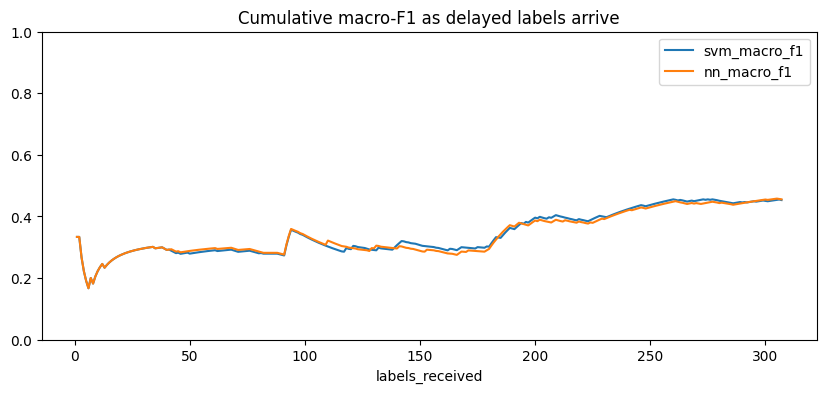

In [9]:
class WindowStream:
    def __init__(self):
        self.buffer=[];self.last_time=None;self.segment=0;self.resets=0
    def push(self,timestamp,values,row_id):
        values=np.asarray(values,dtype=float)
        if not np.isfinite(timestamp) or values.shape!=(6,) or not np.isfinite(values).all():
            self.buffer=[];self.last_time=None;self.resets+=1
            return None
        if self.last_time is not None and (timestamp<self.last_time or timestamp-self.last_time>MAX_GAP_SECONDS):
            self.buffer=[];self.segment+=1;self.resets+=1
        self.last_time=timestamp
        self.buffer.append((timestamp,values,row_id))
        if len(self.buffer)<WINDOW:return None
        block=self.buffer;self.buffer=[]
        return {'values':np.stack([r[1] for r in block]),'end_row':row_id,
                'timestamp':timestamp,'elapsed':timestamp-block[0][0]}
# Warm-up excluded from latency measurements.
for _ in range(10):svm.predict(Zte[:1]);predict_nn(Zte[:1])
stream=WindowStream();pending=deque();LABEL_DELAY=3
observed=[];scored={'SVM':[],'Neural network':[]};labelled_y=[];curve=[];stream_vectors=[]
label_by_row=test_raw.set_index('source_row').Class.to_dict()
def reveal(item,arrival):
    true=int(encoder.transform([label_by_row[item['end_row']]])[0]);labelled_y.append(true)
    for name in scored:scored[name].append(item[name])
    curve.append({'labels_received':len(labelled_y),'arrival_event':arrival,
      'svm_macro_f1':f1_score(labelled_y,scored['SVM'],labels=np.arange(K),average='macro',zero_division=0),
      'nn_macro_f1':f1_score(labelled_y,scored['Neural network'],labels=np.arange(K),average='macro',zero_division=0)})
for row in test_raw.itertuples(index=False):
    item=stream.push(float(row.Timestamp),[getattr(row,k) for k in SENSORS],int(row.source_row))
    if item is None:continue
    t0=time.perf_counter_ns();feat=feature_vector(item['values']);z=scaler.transform(feat[None,:]).astype(np.float32)
    prep_ms=(time.perf_counter_ns()-t0)/1e6
    stream_vectors.append(feat)
    record={'event':len(observed)+1,'end_row':item['end_row'],'timestamp':item['timestamp'],'collection_seconds':item['elapsed'],'preprocessing_ms':prep_ms}
    for name,fn in [('SVM',svm.predict),('Neural network',predict_nn)]:
        t0=time.perf_counter_ns();record[name]=int(fn(z)[0]);record[name+'_inference_ms']=(time.perf_counter_ns()-t0)/1e6
    observed.append(record);pending.append(record)
    if len(pending)>LABEL_DELAY:reveal(pending.popleft(),len(observed))
# End-of-recording drain: late labels arrive after all sensor events.
while pending:reveal(pending.popleft(),len(observed)+LABEL_DELAY)
replay=pd.DataFrame(observed);learning=pd.DataFrame(curve)
assert np.allclose(np.stack(stream_vectors),Xte)
for name in scored:assert np.array_equal(replay[name].to_numpy(),predictions[name]),'Offline/stream predictions differ'
assert np.array_equal(labelled_y,yte)
latency=[]
for name in scored:
    total=replay.preprocessing_ms+replay[name+'_inference_ms']
    latency.append({'model':name,'p50_processing_ms':total.median(),'p95_processing_ms':total.quantile(.95),
      'compute_capacity_windows_per_second':1000/total.mean()})
display(pd.DataFrame(latency));print('Emitted windows:',len(replay),'continuity resets:',stream.resets)
print('Timing is local microbenchmark capacity, not an end-to-end service throughput guarantee.')
learning.plot(x='labels_received',y=['svm_macro_f1','nn_macro_f1'],figsize=(10,4),title='Cumulative macro-F1 as delayed labels arrive');plt.ylim(0,1);plt.show()
replay.to_csv(OUT/'stream_predictions.csv',index=False);learning.to_csv(OUT/'delayed_label_metrics.csv',index=False)
pd.DataFrame(latency).to_csv(OUT/'latency.csv',index=False)

## 7. Monitoring and behavioral checks
Monitored feature shift without needing labels. Compare each 30-window test block's mean to the training mean in training-standard-deviation units. A shift above 0.5 is an illustrative review flag—not a statistically calibrated drift detector or proof that the model is wrong.

Because test recordings are ordered by class, cumulative metrics can change simply as class composition changes. Interpret monitoring plots in that context. Test malformed readings and continuity resets, then verify that streaming predictions exactly reproduce the offline pipeline.

,window_end,mean_absolute_standardized_shift,features_over_0_5
0,30,0.453917,17
1,60,0.304669,10
2,90,0.167798,0
3,120,0.357641,12
4,150,0.213118,0
5,180,0.276895,4
6,210,0.189012,2
7,240,0.193778,1
8,270,0.427441,16
9,300,0.392861,16


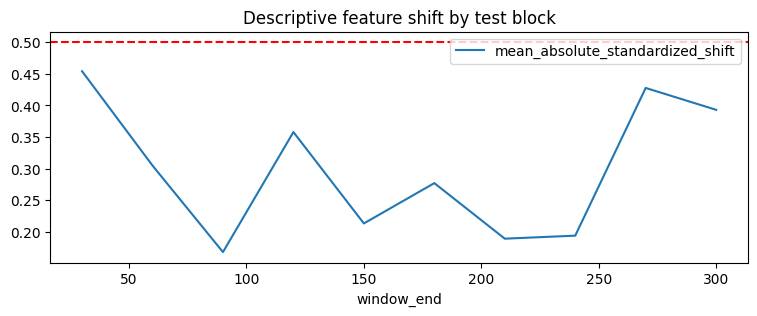

PASS: purge separation, train-only scaler, malformed-input reset, time-gap reset, streaming/offline feature equality and prediction equality.


In [10]:
shift=[]
for start in range(0,len(Zte)-29,30):
    effect=np.abs(Zte[start:start+30].mean(axis=0))
    shift.append({'window_end':start+30,'mean_absolute_standardized_shift':effect.mean(),
      'features_over_0_5':int((effect>.5).sum())})
shift=pd.DataFrame(shift);display(shift)
shift.plot(x='window_end',y='mean_absolute_standardized_shift',figsize=(9,3),title='Descriptive feature shift by test block');plt.axhline(.5,color='red',ls='--');plt.show()
s=WindowStream()
for i in range(WINDOW-1):assert s.push(i*.5,np.zeros(6),i) is None
assert s.push(20,np.zeros(6),99) is None and len(s.buffer)==1
assert s.push(20.5,[np.nan]*6,100) is None and len(s.buffer)==0
assert s.push(21,np.zeros(6),101) is None
assert all(len(set(range(int(r.start_row),int(r.end_row)+1)) & set(val_part.source_row))==0 for r in mtr.itertuples())
print('PASS: purge separation, train-only scaler, malformed-input reset, time-gap reset, streaming/offline feature equality and prediction equality.')
shift.to_csv(OUT/'feature_shift.csv',index=False)

## Recorded-run findings
- **Baseline:** macro-F1 0.195; accuracy 0.414; aggressive recall 0.000.
- **SVM:** macro-F1 0.453; accuracy 0.485; aggressive recall 0.728.
- **Neural network:** macro-F1 0.455; accuracy 0.495; aggressive recall 0.741.

These values come from the included local run, not an assumed target. The sample is small and validation is within recording; reproduce the run and collect independent driver data before drawing broader conclusions.

**Decision:** advance the model comparison to a richer dataset; do not deploy on the strength of this benchmark alone.

## 8. Interpretation and limits
- Use the final table to compare macro-F1 and aggressive recall with processing latency. A faster model may still miss more aggressive windows.
- There are only a few short recordings and no verified driver identities. Source-file separation does not guarantee different drivers, devices or environments.
- Validation comes from tails of the same training segments; tune sparingly and confirm on a new collection.
- A ten-reading window introduces collection delay; this system cannot support claims of instantaneous intervention.
- Phone placement, vehicle type, road surface and sensor calibration can change signals. The 2 Hz recordings do not resolve every short maneuver.
- Timestamp units are coarse, so the notebook uses per-reading differences rather than presenting them as physically calibrated jerk.
- There are no crash outcomes or insurance loss labels. Do not infer accident probability or pricing suitability.

**Next experiment:** collect driver/trip IDs and use leave-one-driver-out evaluation; evaluate a one-dimensional CNN on raw windows; compare several neural-network seeds; test explicitly simulated packet loss separately from untouched test results.

**Your research conclusion:** After running, explain which model you would advance, which failures matter most, and what additional evidence you need. Report the actual dataset size and split, not only a headline accuracy.

In [12]:
summary=metrics.set_index('model')
print('Held-out macro-F1:')
for name,row in summary.iterrows():print(f"{name}: {row.macro_f1:.3f}; aggressive recall: {row.aggressive_recall:.3f}")
print('Interpretation: this is a recording-level prototype comparison; collect independently identified drivers before claiming generalization.')
# Export model artifacts and the exact preprocessing contract.
joblib.dump(svm,OUT/'svm.joblib');joblib.dump(scaler,OUT/'scaler.joblib')
torch.save(net.state_dict(),OUT/'neural_network_state.pt')
contract={'classes':classes.tolist(),'sensor_order':SENSORS,'feature_names':FEATURE_NAMES,
 'window_readings':WINDOW,'stride':STRIDE,'max_gap_seconds':MAX_GAP_SECONDS,'selected_svm':best_svm_key,
 'selected_nn_epoch':best_epoch,'seed':SEED,'nn_architecture':[42,64,32,3],
 'source':'https://www.kaggle.com/datasets/outofskills/driving-behavior',
 'evaluation_scope':'Publisher test file; driver independence unverified'}
(OUT/'model_contract.json').write_text(json.dumps(contract,indent=2))
import importlib.metadata as im
versions={k:im.version(k) for k in ['numpy','pandas','scikit-learn','matplotlib','torch','joblib']}
(OUT/'environment.json').write_text(json.dumps(versions,indent=2));print(versions)
print('Only load serialized models from a trusted source.')

Held-out macro-F1:
Baseline: 0.195; aggressive recall: 0.000
SVM: 0.453; aggressive recall: 0.728
Neural network: 0.455; aggressive recall: 0.741
Interpretation: this is a recording-level prototype comparison; collect independently identified drivers before claiming generalization.
{'numpy': '2.4.6', 'pandas': '2.2.3', 'scikit-learn': '1.6.1', 'matplotlib': '3.10.0', 'torch': '2.11.0+cpu', 'joblib': '1.6.0'}
Only load serialized models from a trusted source.
